# 02b — Extraction evolution logs (GA and NSGA-II)

**Section:** between rule extraction and the evaluation layer
**Inputs:** `artifacts/rules/logs/*_generations.csv`, `*_runs.csv` and `artifacts/rules/runs/*_run_fronts.json`, written by `src/extraction/run_logged.py`
**Why this exists:** the original `ga.py` / `nsga.py` runs saved only the pooled rules, so there was no record of how the searches evolved. `run_logged.py` repeats the **same** extraction (same seeds, operators and parameters, calling `run_ga` / `run_nsga2` unchanged) and records every generation of every run. The pooled rules it produced were compared with the shipped pools (`*_repro_check.txt`) and are identical, so nothing downstream had to be redone.

**How to read the numbers.** 30 independent runs per (extractor, condition), 50 generations each. Curves show the median across runs with the inter-quartile band. A rule always predicts one class, so macro-F1 fidelity is `p/(1+p)` (p = share of covered rows in the rule's class): it can only exceed 0.5 if the covered region is perfectly pure, and 0.46 / 0.49 correspond to about 85% / 96% agreement with the model.

In [1]:
import os, sys, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")            # run from the repo root so relative paths match the pipeline
sys.path.insert(0, ".")
import numpy as np, pandas as pd

import matplotlib.pyplot as plt
LOG = Path("artifacts/rules/logs"); RUNS = Path("artifacts/rules/runs"); FIG = Path("artifacts/reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
C = {"baseline": "#2a78d6", "sam": "#eb6834"}          # validated categorical slots 1-2
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "font.size": 9})
g = {(e, c): pd.read_csv(LOG / f"{e}_{c}_generations.csv") for e in ("ga", "nsga") for c in ("baseline", "sam")}
r = {(e, c): pd.read_csv(LOG / f"{e}_{c}_runs.csv") for e in ("ga", "nsga") for c in ("baseline", "sam")}
for k, v in g.items(): print(k, v.shape, "runs:", v.run_id.nunique())

def band(ax, df, col, cond, label=None):
    s = df.groupby("gen")[col].quantile([.25, .5, .75]).unstack()
    ax.plot(s.index, s[.5], color=C[cond], lw=2, label=label or cond)
    ax.fill_between(s.index, s[.25], s[.75], color=C[cond], alpha=.18, lw=0)

('ga', 'baseline') (1530, 20) runs: 30
('ga', 'sam') (1530, 20) runs: 30
('nsga', 'baseline') (1530, 19) runs: 30
('nsga', 'sam') (1530, 19) runs: 30


## 1. GA: fitness over generations and the aging effect

`ga.py` replaces individuals older than `max_age = 8` generations by random immigrants. Children are clones that inherit their parent's `age`, so in a population that starts all at age 0 every individual ages in lockstep and the **whole population** is replaced at generation 9, 18, 27, 36 and 45. The curves below test that directly.

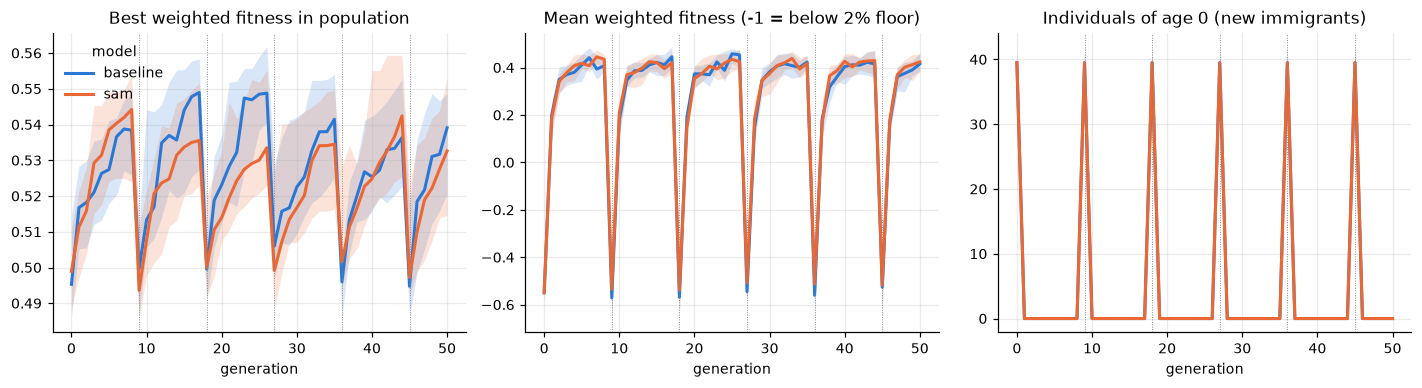

generations at which the entire population was replaced in some run: [np.int64(9), np.int64(18), np.int64(27), np.int64(36), np.int64(45)]
share of the 60 GA runs with a full replacement at those generations:
 gen
9     1.0
18    1.0
27    1.0
36    1.0
45    1.0

full replacements at any OTHER generation: 0


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for c in ("baseline", "sam"):
    band(ax[0], g[("ga", c)], "fit_max", c)
    band(ax[1], g[("ga", c)], "fit_avg", c)
    band(ax[2], g[("ga", c)], "n_age0", c)
ax[0].set_title("Best weighted fitness in population"); ax[1].set_title("Mean weighted fitness (-1 = below 2% floor)")
ax[2].set_title("Individuals of age 0 (new immigrants)")
for a in ax:
    a.set_xlabel("generation")
    for x in (9, 18, 27, 36, 45): a.axvline(x, color="grey", lw=.6, ls=":")
ax[0].legend(frameon=False, title="model")
plt.tight_layout(); plt.savefig(FIG / "ga_evolution.png"); plt.show()

# quantitative check of the lockstep-replacement hypothesis
d = pd.concat([g[("ga", c)].assign(condition=c) for c in ("baseline", "sam")])
d["all_new"] = d.n_age0 == d.popsize
wipe_gens = sorted(d.loc[d.all_new & (d.gen > 0), "gen"].unique())
share = d.loc[d.gen.isin(wipe_gens)].groupby("gen").all_new.mean()
print("generations at which the entire population was replaced in some run:", wipe_gens)
print("share of the 60 GA runs with a full replacement at those generations:\n", share.round(2).to_string())
print("\nfull replacements at any OTHER generation:", int(d.loc[d.all_new & (d.gen > 0) & ~d.gen.isin(wipe_gens)].shape[0]))

**Reading.** If the population is entirely age 0 at generations 9, 18, 27, 36 and 45 in (nearly) every run, then each GA run is effectively **five or six short searches of about nine generations**, with the 10-slot HallOfFame carrying the best rules across the restarts. The rules that reach the pool are therefore the best of several short restarts, not the end of one 50-generation search. This is a property of the implemented algorithm, not of the data; it is reported as a limitation and a future-work item (stagger or reset ages for offspring).

## 2. GA: what the search finds, and how diverse the population is

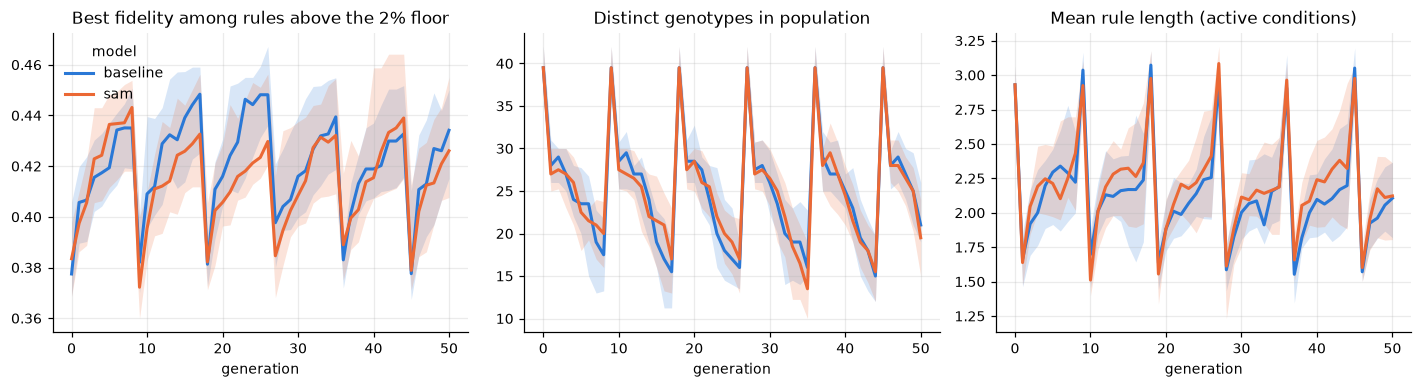

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for c in ("baseline", "sam"):
    band(ax[0], g[("ga", c)], "best_fidelity_valid", c)
    band(ax[1], g[("ga", c)], "n_unique_genotypes", c)
    band(ax[2], g[("ga", c)], "mean_length", c)
ax[0].set_title("Best fidelity among rules above the 2% floor"); ax[1].set_title("Distinct genotypes in population")
ax[2].set_title("Mean rule length (active conditions)")
for a in ax: a.set_xlabel("generation")
ax[0].legend(frameon=False, title="model")
plt.tight_layout(); plt.savefig(FIG / "ga_fidelity_diversity.png"); plt.show()

## 3. NSGA-II: convergence and diversity

NSGA-II logs every run with `front_size = 40 = pop`, i.e. the whole population is in front 0. Identical individuals do not dominate each other, so a population of copies of a handful of rules still reports a full front. `front0_unique` counts the distinct rules in that front.

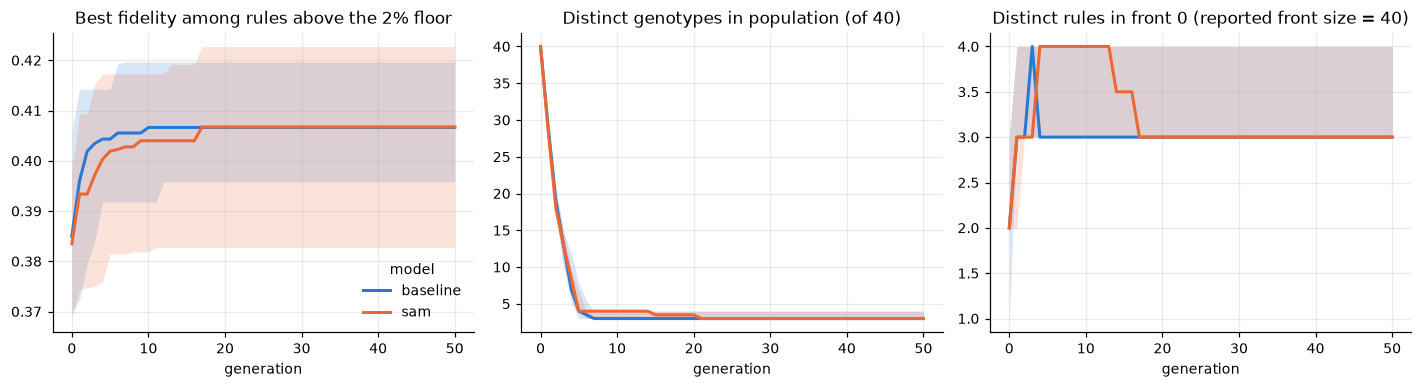

condition,baseline,sam
median generation best fidelity is reached,4.0,4.0
runs reaching it by gen 15,29.0,29.0
median distinct genotypes at gen 50 (of 40),3.0,3.0
median distinct front-0 rules at gen 50,3.0,3.0
runs with <= 5 distinct front-0 rules,30.0,29.0


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for c in ("baseline", "sam"):
    band(ax[0], g[("nsga", c)], "best_above_fidelity", c)
    band(ax[1], g[("nsga", c)], "n_unique_genotypes", c)
    band(ax[2], g[("nsga", c)], "front0_unique", c)
ax[0].set_title("Best fidelity among rules above the 2% floor"); ax[1].set_title("Distinct genotypes in population (of 40)")
ax[2].set_title("Distinct rules in front 0 (reported front size = 40)")
for a in ax: a.set_xlabel("generation")
ax[0].legend(frameon=False, title="model")
plt.tight_layout(); plt.savefig(FIG / "nsga_evolution.png"); plt.show()

rows = []
for c in ("baseline", "sam"):
    d = g[("nsga", c)]
    last = d[d.gen == d.gen.max()]
    # generation after which the best fidelity never improves again, per run
    conv = d.groupby("run_id").apply(lambda x: int(x.loc[x.best_above_fidelity.fillna(-1) >= x.best_above_fidelity.max() - 1e-12, "gen"].min()))
    rows.append({"condition": c, "median generation best fidelity is reached": conv.median(),
                 "runs reaching it by gen 15": int((conv <= 15).sum()),
                 "median distinct genotypes at gen 50 (of 40)": last.n_unique_genotypes.median(),
                 "median distinct front-0 rules at gen 50": last.front0_unique.median(),
                 "runs with <= 5 distinct front-0 rules": int((last.front0_unique <= 5).sum())})
pd.DataFrame(rows).set_index("condition").T

## 4. Final comparison across the 30 independent runs

Each run is an independent replicate (different seed), so per-run results are the properly independent sample. For every run: the best fidelity (train) among its final front.

                     count    mean     std     min     25%     50%     75%     max
extractor condition                                                               
ga        baseline    30.0  0.4680  0.0072  0.4524  0.4640  0.4691  0.4724  0.4800
          sam         30.0  0.4709  0.0134  0.4393  0.4617  0.4704  0.4816  0.4914
nsga      baseline    30.0  0.4092  0.0220  0.3747  0.3958  0.4066  0.4197  0.4617
          sam         30.0  0.4065  0.0261  0.3621  0.3827  0.4067  0.4228  0.4553


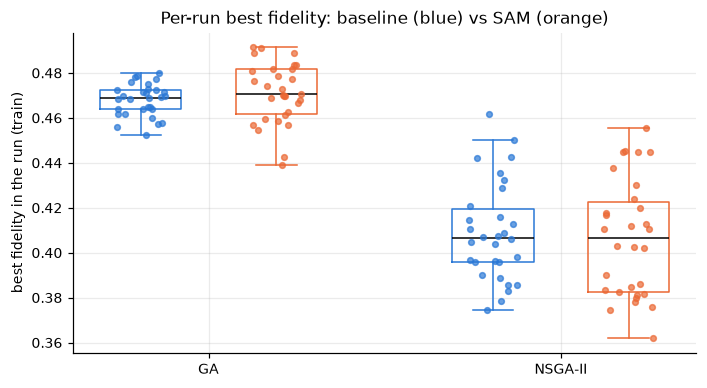

In [5]:
best = []
for e in ("ga", "nsga"):
    for c in ("baseline", "sam"):
        fr = json.load(open(RUNS / f"{e}_{c}_run_fronts.json"))
        for run, rules in fr.items():
            best.append({"extractor": e, "condition": c, "run_id": int(run),
                         "best_fidelity_train": max(x["fidelity_f1"] for x in rules), "front_rules": len(rules)})
best = pd.DataFrame(best)
best.to_csv(Path("artifacts/reports") / "per_run_best_fidelity.csv", index=False)
print(best.groupby(["extractor", "condition"]).best_fidelity_train.describe().round(4).to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.6))
pos = {("ga","baseline"):0, ("ga","sam"):1, ("nsga","baseline"):2.6, ("nsga","sam"):3.6}
for k, x in pos.items():
    v = best[(best.extractor == k[0]) & (best.condition == k[1])].best_fidelity_train
    ax.boxplot(v, positions=[x], widths=.6, showfliers=False, medianprops=dict(color="black"),
               boxprops=dict(color=C[k[1]]), whiskerprops=dict(color=C[k[1]]), capprops=dict(color=C[k[1]]))
    ax.scatter(np.full(len(v), x) + np.random.default_rng(0).uniform(-.18, .18, len(v)), v, s=14, color=C[k[1]], alpha=.7, zorder=3)
ax.set_xticks([.5, 3.1]); ax.set_xticklabels(["GA", "NSGA-II"]); ax.set_ylabel("best fidelity in the run (train)")
ax.set_title("Per-run best fidelity: baseline (blue) vs SAM (orange)")
plt.tight_layout(); plt.savefig(FIG / "per_run_best_fidelity.png"); plt.show()